# **Customer Segmentation Analysis**

**Goal:** Analyze a customer dataset to identify distinct segments based on income and spending score. The insights can be used to design more personalized and effective marketing strategies.

**Analysis steps:**
1.  **Load libraries & dataset:** Import the required libraries and load the customer data.
2.  **Segmentation analysis:** Group customers with K-Means clustering.
3.  **Demographic analysis:** Examine the influence of gender and age on shopping behavior.
4.  **Conclusions & recommendations:** Summarize the findings and give business recommendations.

> **Data:** reads `data/processed/mall_customers_clean.csv`, generated by `module-03-data-cleaning/data_cleaning.ipynb` (a copy is already included; see `data/README.md`).

### **Import Libraries**
Import all Python libraries needed for data analysis and visualization.

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

## **1. Load the Dataset**
Load the cleaned dataset produced in Module 3 into a pandas DataFrame.

In [2]:
DATA_PATH = Path('../data/processed/mall_customers_clean.csv')

df = pd.read_csv(DATA_PATH)
print(df.head())

   customer_id  gender  age  annual_income_k_usd  spending_score
0            1    Male   19                   15              39
1            2    Male   21                   15              81
2            3  Female   20                   16               6
3            4  Female   23                   16              77
4            5  Female   31                   17              40


## **2. Customer Segmentation with K-Means Clustering**

To uncover hidden patterns, we group customers into **5 distinct segments** with K-Means. The grouping is based on two features: `annual_income_k_usd` and `spending_score`.

### **Customer Segment Visualization**

The clustering result is shown as a scatter plot so each segment's position is easy to see.

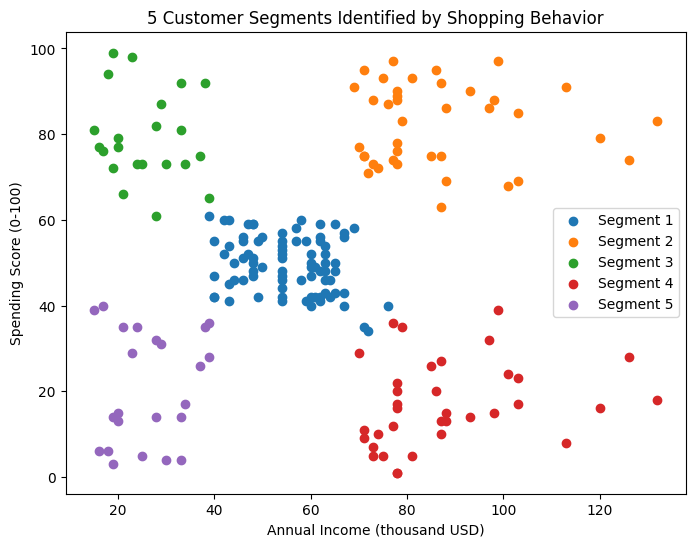

In [3]:
kmeans = KMeans(n_clusters=5, random_state=42)
df['cluster'] = kmeans.fit_predict(df[['annual_income_k_usd', 'spending_score']])

plt.figure(figsize=(8, 6))

for cluster in sorted(df['cluster'].unique()):
    cluster_data = df[df['cluster'] == cluster]
    plt.scatter(cluster_data['annual_income_k_usd'], cluster_data['spending_score'], label=f"Segment {cluster + 1}")

plt.title("5 Customer Segments Identified by Shopping Behavior", fontsize=12)
plt.xlabel("Annual Income (thousand USD)")
plt.ylabel("Spending Score (0-100)")
plt.legend()
plt.show()

### **Insights from the Segmentation**

The visualization above shows 5 clear customer segments (numbering follows the K-Means run with `random_state=42`):
* **Segment 1 (Average):** The largest group, in the middle, with moderate income and spending.
* **Segment 2 (Ideal Target):** The most attractive customers, with high income and a high spending score.
* **Segment 3 (Low-Income Spenders):** Customers with low income who still spend freely.
* **Segment 4 (High-Income Savers):** Customers with high income but a low spending score.
* **Segment 5 (Low-Income Savers):** Customers who are careful with money and have low income.

These insights are valuable for marketing personalization.

## **3. Demographic Analysis: Shopping Behavior by Gender**

Next, we check whether gender has a significant effect on the average spending score.

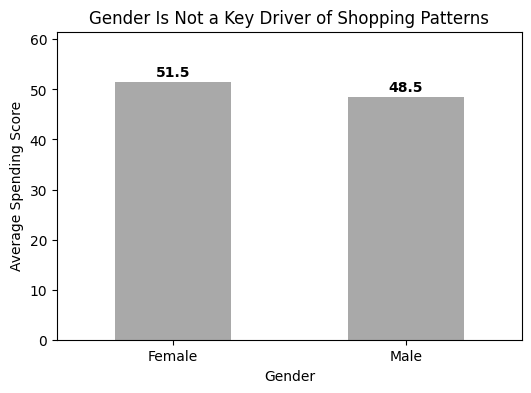

In [4]:
avg_spending_by_gender = df.groupby("gender", observed=True)["spending_score"].mean()

plt.figure(figsize=(6, 4))
avg_spending_by_gender.plot(kind="bar", color=["darkgray"])

for i, val in enumerate(avg_spending_by_gender):
    plt.text(i, val + 1, f"{val:.1f}", ha='center', fontweight='bold')

plt.title("Gender Is Not a Key Driver of Shopping Patterns")
plt.ylabel("Average Spending Score")
plt.xlabel("Gender")
plt.xticks(rotation=0)
plt.ylim(0, avg_spending_by_gender.max() + 10)
plt.show()

As the chart title and the nearly identical averages show, there is **no significant difference** in shopping behavior between male and female customers in this dataset. A marketing strategy that focuses on gender alone is therefore unlikely to be effective.

## **4. Demographic Analysis: Customer Age Distribution**

This analysis identifies which age group makes up the largest part of the customer base.

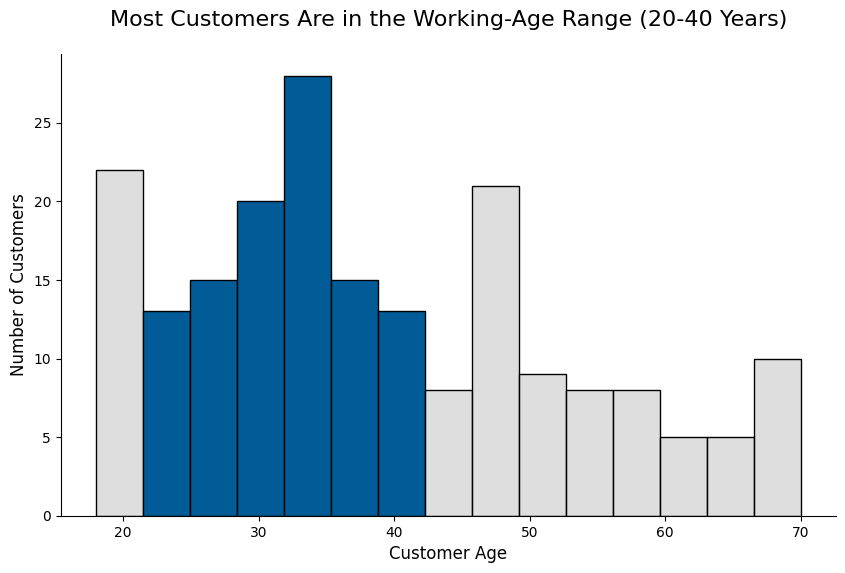

In [5]:
plt.figure(figsize=(10, 6))
ax = sns.histplot(data=df, x='age', bins=15, kde=False, color='lightgray')

for bar in ax.patches:
    # get_x() returns the starting position of the bar on the x-axis
    if bar.get_x() >= 20 and bar.get_x() < 40:
        bar.set_facecolor('#005b96')  # dark blue highlight

plt.title('Most Customers Are in the Working-Age Range (20-40 Years)', fontsize=16, pad=20)
plt.xlabel('Customer Age', fontsize=12)
plt.ylabel('Number of Customers', fontsize=12)
sns.despine()
plt.show()

### **Insight**

The histogram clearly highlights that **most customers are between 20 and 40 years old**. The main target market is therefore young to early-middle-aged adults, who should be the primary focus of marketing campaigns.

## **5. Conclusions and Recommendations**

Based on the overall analysis:

**Key conclusions:**
1.  **Segmentation matters more than demographics:** Shopping behavior is better explained by the combination of income and spending score (5 segments) than by gender alone.
2.  **The core market is young adults:** The largest customer base is concentrated in the 20-40 age range.

**Business recommendations:**
* **Adopt segment-based marketing:** Instead of mass campaigns, create different promotions for each segment. For example, offer premium products and a loyalty program to the "Ideal Target" segment, and discounts or installment offers to the "Low-Income Spenders" segment.
* **Focus communication on young adults:** Direct marketing effort, ad channel selection, and tone of voice toward the 20-40 age group to maximize reach and relevance.